In [2]:
import numpy as np

from matplotlib import pyplot as plt

In [3]:
test_cases = [
    'test_diam_0_10',
    'test_noise_0_25',
    'test_density_0_20',
    'test_disp_noise_0',
    'test_disp_noise_5',
    'test_disp_noise_10',
    'test_disp_noise_15',
    'test_disp_noise_20',
    'test_disp_noise_25'
]

In [4]:
openpiv_data = {}

num_pairs = 500
deform = 'symmetric'
interp = 'lagrange'
order = 3

for test in test_cases:
    print(test)
    data_pck = {}
    
    for corr_type in ['circular', 'linear']:
        bias_data = []
        rmse_data = []
        
        for ind in range(num_pairs):
            data_name = f'{corr_type}_{deform}_{interp}_k_{order}_vec_{str(ind+1).zfill(4)}.txt'
            piv_vel = f'./results/openpiv_cxx/{test}/' + data_name

            # Due to the size of the stored files, I had to remove redundant data.
            # So, we have to choose which directory has a full dataset, and which
            # only has a single vector field
            if 'disp' in test:
                ref_vel = './data/ground_truth/test_disp_noise/' + 'image_{:04d}disp.npy'.format(ind+1)
            else:
                ref_vel = './data/ground_truth/test_all_others/' + 'image_{:04d}disp.npy'.format(1)
            
            measured = np.loadtxt(piv_vel, delimiter='\t', skiprows=1)
            expected = np.load(ref_vel)
            
            expected_u = expected[0]
            expected_v = expected[1]
        
            y = measured[:, 0]
            x = measured[:, 1]
            u = measured[:, 2]
            v = measured[:, 3]

            vel_m = np.hypot(u, v)
    
            vel_e = np.hypot(
                expected_u[y.astype(int), x.astype(int)],
                expected_v[y.astype(int), x.astype(int)]
            ).ravel()
        
            err = vel_m - vel_e
            
            bias = np.nanmean(err)
            rmse = np.sqrt(np.nanmean(np.square(err)))

            bias_data.append(bias)
            rmse_data.append(rmse)
            
        data_pck[corr_type] = {'bias': bias_data, 'rmse': rmse_data}
        
    openpiv_data[test] = data_pck

test_diam_0_10


C:\Users\Research\AppData\Local\Temp\ipykernel_3944\78396780.py:48: RuntimeWarning: Mean of empty slice
  bias = np.nanmean(err)
C:\Users\Research\AppData\Local\Temp\ipykernel_3944\78396780.py:49: RuntimeWarning: Mean of empty slice
  rmse = np.sqrt(np.nanmean(np.square(err)))


test_noise_0_25
test_density_0_20
test_disp_noise_0
test_disp_noise_5
test_disp_noise_10
test_disp_noise_15
test_disp_noise_20
test_disp_noise_25


In [5]:
pivlab_data = {}

num_pairs = 500

for test in test_cases:
    print(test)
    data_pck = {}
    
    for corr_type in ['normal', 'high']:
        bias_data = []
        rmse_data = []
        
        for ind in range(num_pairs):
            data_name = f'PIVlab_{str(ind+1).zfill(4)}.txt'
            piv_vel = f'./results/pivlab/{test}/{corr_type}/' + data_name

            # Due to the size of the stored files, I had to remove redundant data.
            # So, we have to choose which directory has a full dataset, and which
            # only has a single vector field
            if 'disp' in test:
                ref_vel = './data/ground_truth/test_disp_noise/' + 'image_{:04d}disp.npy'.format(ind+1)
            else:
                ref_vel = './data/ground_truth/test_all_others/' + 'image_{:04d}disp.npy'.format(1)
                
            measured = np.loadtxt(piv_vel, delimiter='\t', skiprows=1)
            expected = np.load(ref_vel)
            
            expected_u = expected[0]
            expected_v = expected[1]
        
            y = measured[:, 0]
            x = measured[:, 1]
            u = measured[:, 2]
            v = measured[:, 3]

            vel_m = np.hypot(u, v)
    
            vel_e = np.hypot(
                expected_u[y.astype(int), x.astype(int)],
                expected_v[y.astype(int), x.astype(int)]
            ).ravel()
        
            err = vel_m - vel_e
            
            bias = np.nanmean(err)
            rmse = np.sqrt(np.nanmean(np.square(err)))

            bias_data.append(bias)
            rmse_data.append(rmse)
            
        data_pck[corr_type] = {'bias': bias_data, 'rmse': rmse_data}
        
    pivlab_data[test] = data_pck

test_diam_0_10


C:\Users\Research\AppData\Local\Temp\ipykernel_3944\926779603.py:45: RuntimeWarning: Mean of empty slice
  bias = np.nanmean(err)
C:\Users\Research\AppData\Local\Temp\ipykernel_3944\926779603.py:46: RuntimeWarning: Mean of empty slice
  rmse = np.sqrt(np.nanmean(np.square(err)))


test_noise_0_25
test_density_0_20
test_disp_noise_0
test_disp_noise_5
test_disp_noise_10
test_disp_noise_15
test_disp_noise_20
test_disp_noise_25


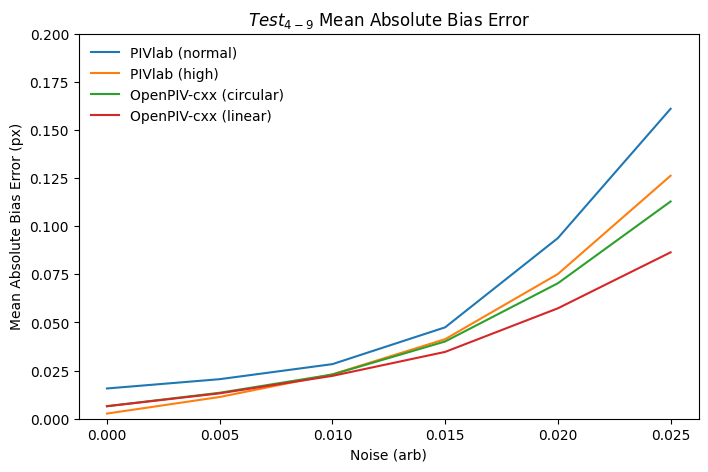

In [24]:
x_data = []
y_data = [
    [],
    [],
    [],
    []
]

for ind, test in enumerate(test_cases, start=1):
    noise_val = test.split('_')[-1]
    noise_val = float(noise_val) / 1000
    x_data.append(noise_val)

    y_data[0].append(np.mean(np.abs(pivlab_data[test]['normal']['bias'])))
    y_data[1].append(np.mean(np.abs(pivlab_data[test]['high']['bias'])))
    y_data[2].append(np.mean(np.abs(openpiv_data[test]['circular']['bias'])))
    y_data[3].append(np.mean(np.abs(openpiv_data[test]['linear']['bias'])))
                    
fig, ax = plt.subplots(figsize=(8, 5))
ax.set_title('$Test_{4-9}$ Mean Absolute Bias Error')

ax.plot(x_data, y_data[0], label='PIVlab (normal)')
ax.plot(x_data, y_data[1], label='PIVlab (high)')
ax.plot(x_data, y_data[2], label='OpenPIV-cxx (circular)')
ax.plot(x_data, y_data[3], label='OpenPIV-cxx (linear)')

ax.set_xlabel('Noise (arb)')
ax.set_ylabel('Mean Absolute Bias Error (px)')
ax.set_ylim(top=0.2, bottom=0.0)
ax.legend(frameon=False, shadow=True)
#plt.savefig(f'test_mean_absolute_bias.png')

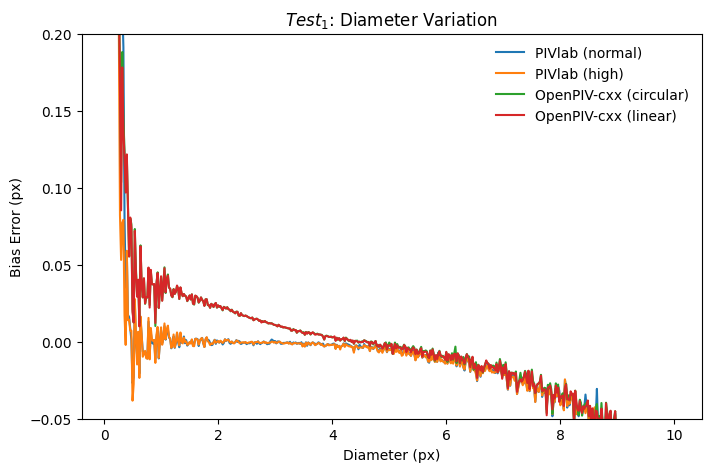

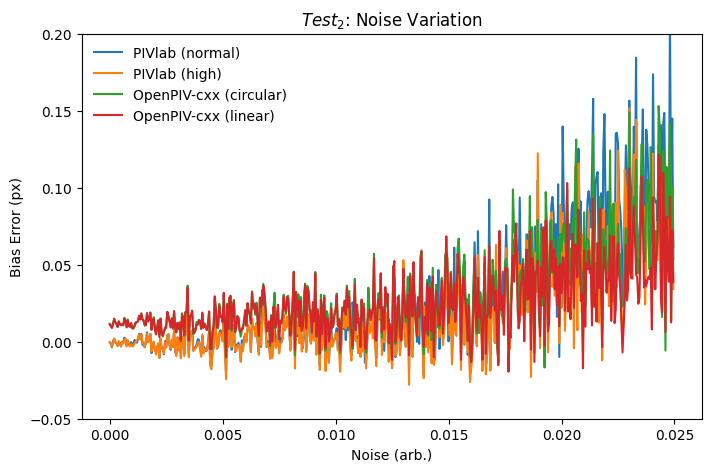

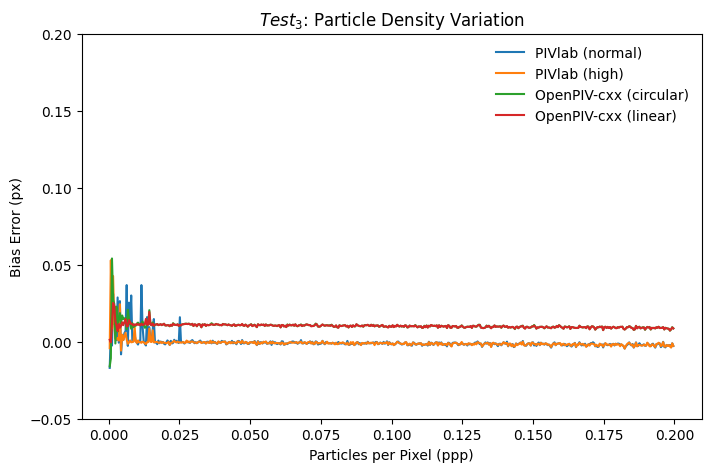

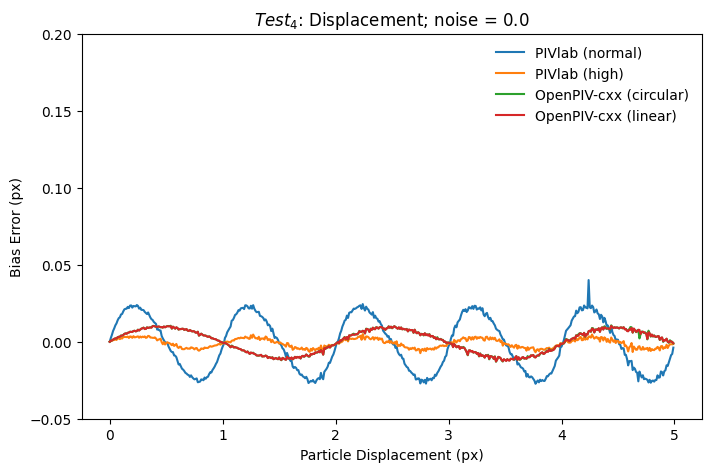

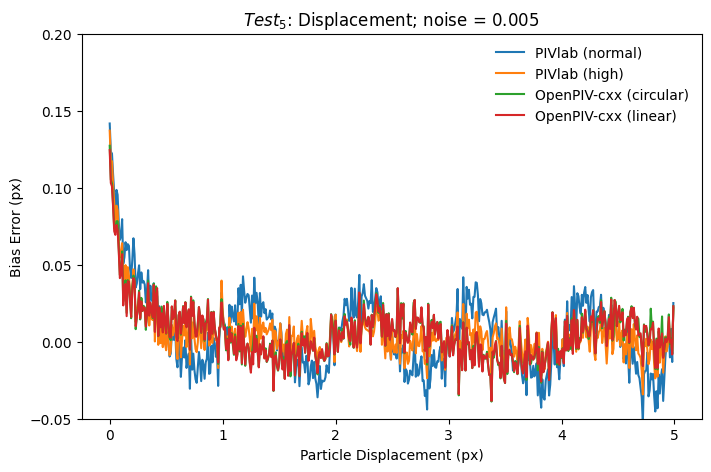

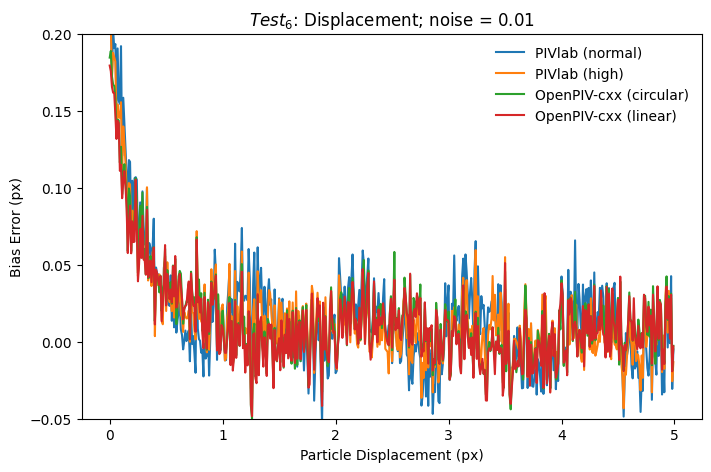

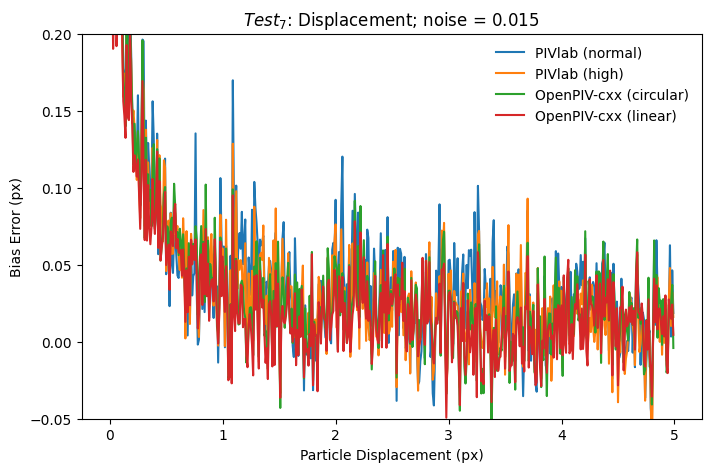

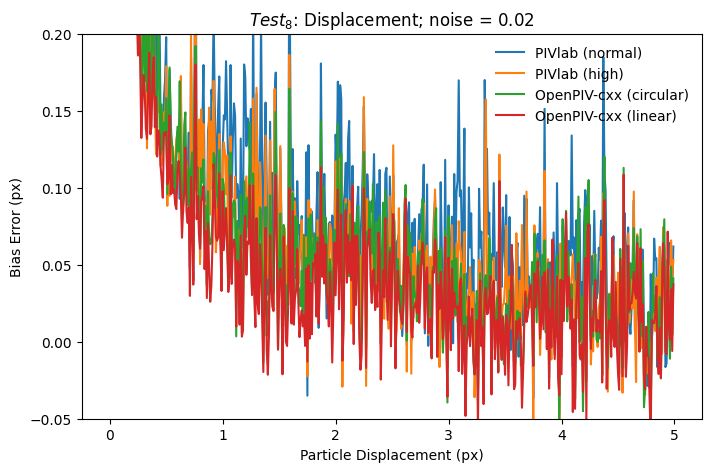

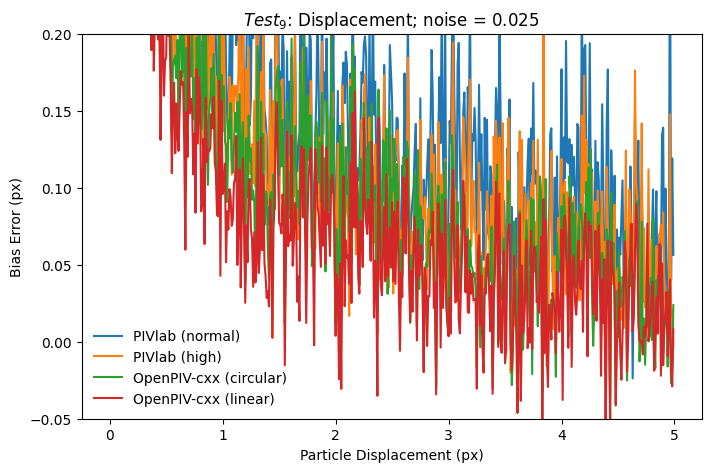

In [13]:
for ind, test in enumerate(test_cases, start=1):
    if 'noise_0_25' in test:
        title = 'Noise Variation'
        x_label = 'Noise (arb.)'
        max_x = 0.025
    elif 'diam' in test:
        title = 'Diameter Variation'
        x_label = 'Diameter (px)'
        max_x = 10
    elif 'den' in test:
        title = 'Particle Density Variation'
        x_label = 'Particles per Pixel (ppp)'
        max_x = 0.2
    else:
        noise_val = test.split('_')[-1]
        noise_val = float(noise_val) / 1000
        title = f'Displacement; noise = {noise_val}'
        x_label = 'Particle Displacement (px)'
        max_x = 5

    x_data = np.linspace(0, max_x, 500, endpoint=False)
    
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.set_title(f'$Test_{ind}$: {title}')
    
    ax.plot(x_data, pivlab_data[test]['normal']['bias'], label='PIVlab (normal)')
    ax.plot(x_data, pivlab_data[test]['high']['bias'], label='PIVlab (high)')
    ax.plot(x_data, openpiv_data[test]['circular']['bias'], label='OpenPIV-cxx (circular)')
    ax.plot(x_data, openpiv_data[test]['linear']['bias'], label='OpenPIV-cxx (linear)')
    
    ax.set_xlabel(x_label)
    ax.set_ylabel('Bias Error (px)')
    ax.set_ylim(top=0.2, bottom=-0.05)
    ax.legend(frameon=False, shadow=True)
    #plt.savefig(f'test_{ind}_bias.png')

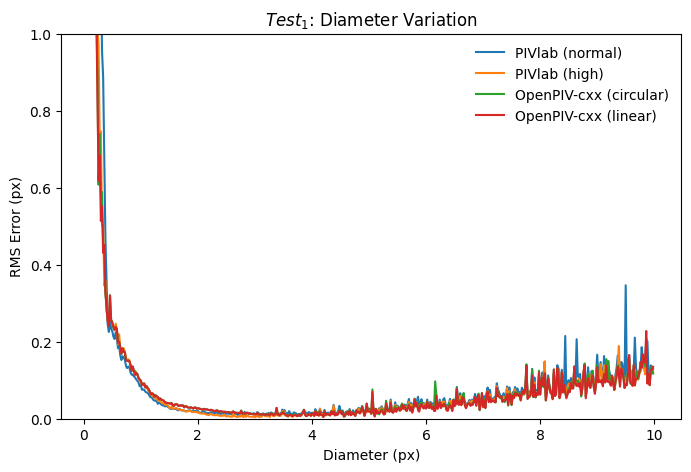

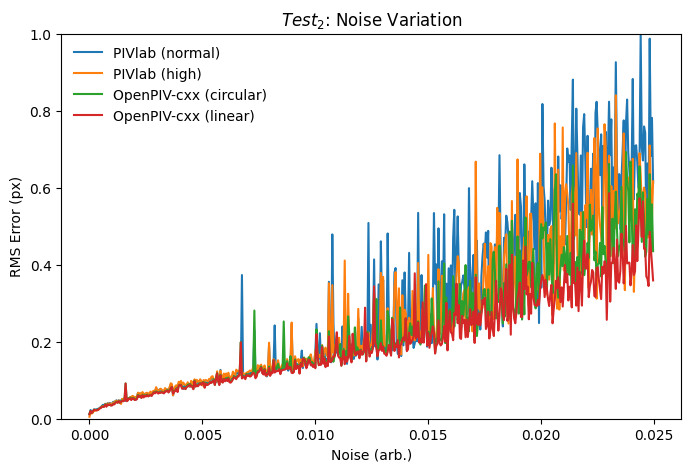

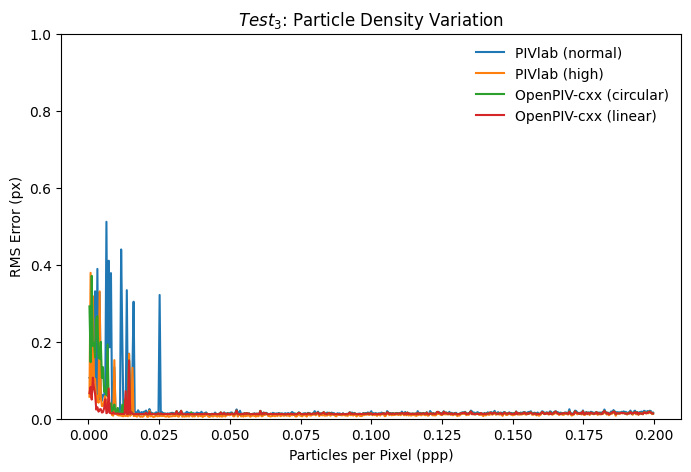

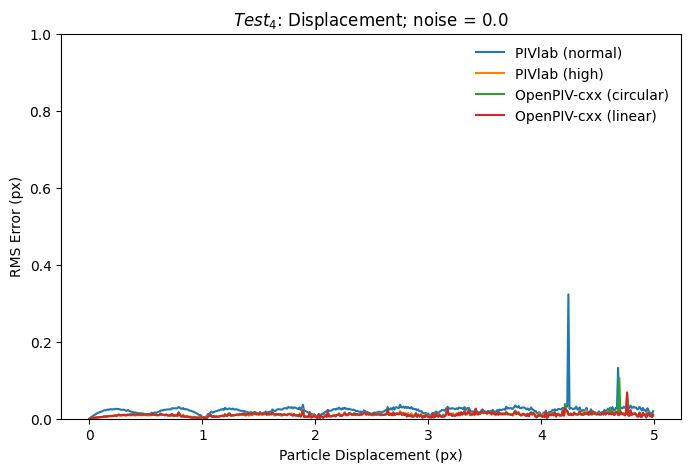

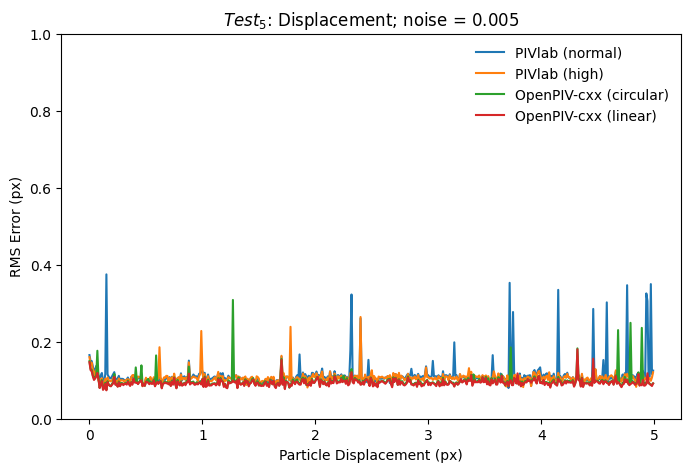

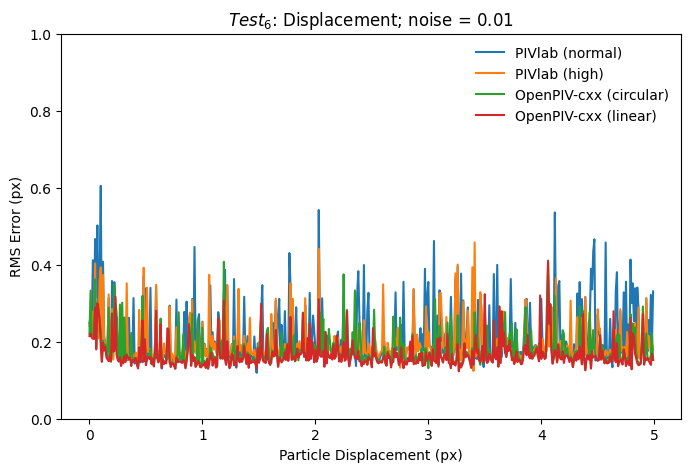

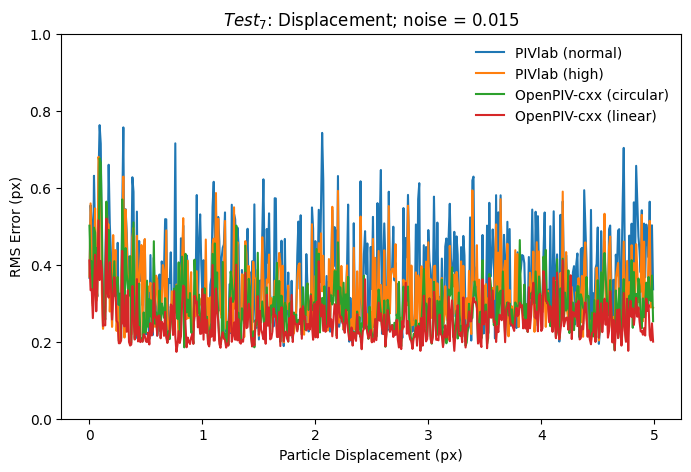

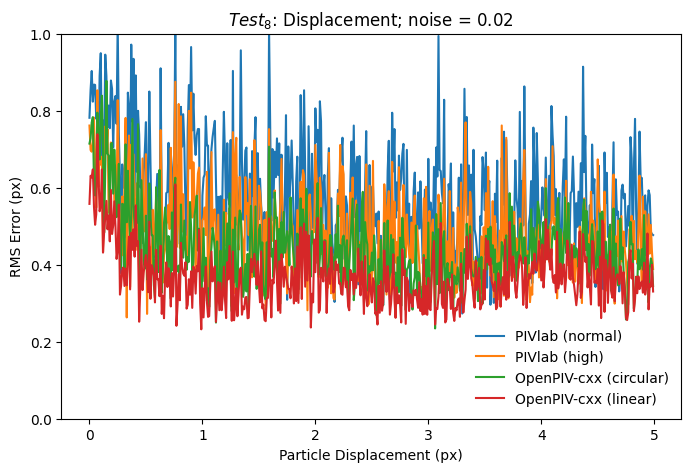

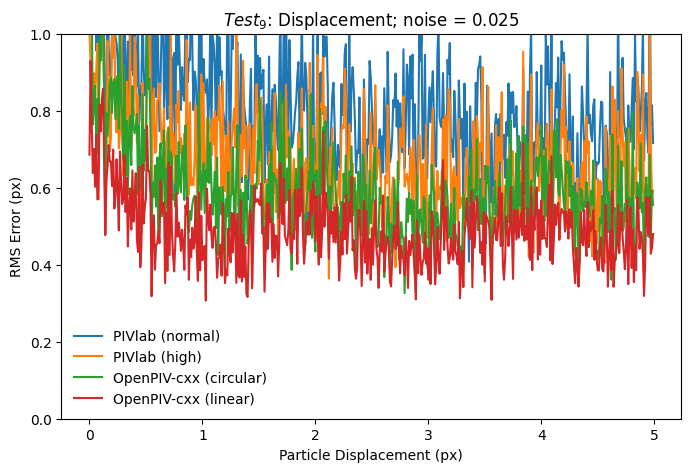

In [14]:
for ind, test in enumerate(test_cases, start=1):
    if 'noise_0_25' in test:
        title = 'Noise Variation'
        x_label = 'Noise (arb.)'
        max_x = 0.025
    elif 'diam' in test:
        title = 'Diameter Variation'
        x_label = 'Diameter (px)'
        max_x = 10
    elif 'den' in test:
        title = 'Particle Density Variation'
        x_label = 'Particles per Pixel (ppp)'
        max_x = 0.2
    else:
        noise_val = test.split('_')[-1]
        noise_val = float(noise_val) / 1000
        title = f'Displacement; noise = {noise_val}'
        x_label = 'Particle Displacement (px)'
        max_x = 5

    x_data = np.linspace(0, max_x, 500, endpoint=False)
    
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.set_title(f'$Test_{ind}$: {title}')
    
    ax.plot(x_data, pivlab_data[test]['normal']['rmse'], label='PIVlab (normal)')
    ax.plot(x_data, pivlab_data[test]['high']['rmse'], label='PIVlab (high)')
    ax.plot(x_data, openpiv_data[test]['circular']['rmse'], label='OpenPIV-cxx (circular)')
    ax.plot(x_data, openpiv_data[test]['linear']['rmse'], label='OpenPIV-cxx (linear)')
    
    ax.set_xlabel(x_label)
    ax.set_ylabel('RMS Error (px)')
    ax.set_ylim(top=1.0, bottom=-0.0)
    ax.legend( frameon=False, shadow=True)
    #plt.savefig(f'test_{ind}_rmse.png')

Timing aquisition was captured in the following way:

Laptop:
 - Performance mode
 - Battery fully charged
 - Batter still on charger

PIVlab:
 - 3 runs on 500 image pairs on normal (w/ and w/o parallel processing)
 - 3 runs on 500 image pairs on high (w/ and w/o parallel processing)
 - Average out times and calculate time per vector in milliseconds

OpenPIV-cxx:
 - 3 runs on 500 image pairs on circular (w/ and w/o multithreading)
 - 3 runs on 500 image pairs on linear (w/ and w/o multithreading)
 - Average out times and calculate time per vector in milliseconds

PIVview:
 - 10 runs on a single image pair (OMP_NUM_THREADS=1)
 - 10 runs on a single image pair (OMP_NUM_THREADS=8)
 - Average out times and calculate time per vector in milliseconds

Note: Due to using the demo version of PIVview, I was not able to perform the complete benchmark and subsequently more accurate timing. Nonetheless, the convergence of the vectors per millisecond after five runs was already quite significant.

In [15]:
pivlab_normal_serial =  0.151
pivlab_high_serial = 0.230
pivlab_normal_parallel = 0.048
pivlab_high_parallel = 0.106
openpiv_cxx_circular_serial = 0.124
openpiv_cxx_linear_serial = 0.168
openpiv_cxx_circular_threaded = 0.079
openpiv_cxx_linear_threaded = 0.096
pivview_serial = 0.332
pivview_threaded = 0.195

categories = [
    'OpenPIV-cxx (circular)', 
    'OpenPIV-cxx (linear)', 
    'PIVlab (normal)',
    'PIVlab (high)', 
    'PIVview'
]

serial = [
    openpiv_cxx_circular_serial,
    openpiv_cxx_linear_serial,
    pivlab_normal_serial,
    pivlab_high_serial,
    pivview_serial
]
threaded = [
    openpiv_cxx_circular_threaded,
    openpiv_cxx_linear_threaded,
    pivlab_normal_parallel,
    pivlab_high_parallel,
    pivview_threaded
]

C:\Users\Research\AppData\Local\Temp\ipykernel_3944\3198242684.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


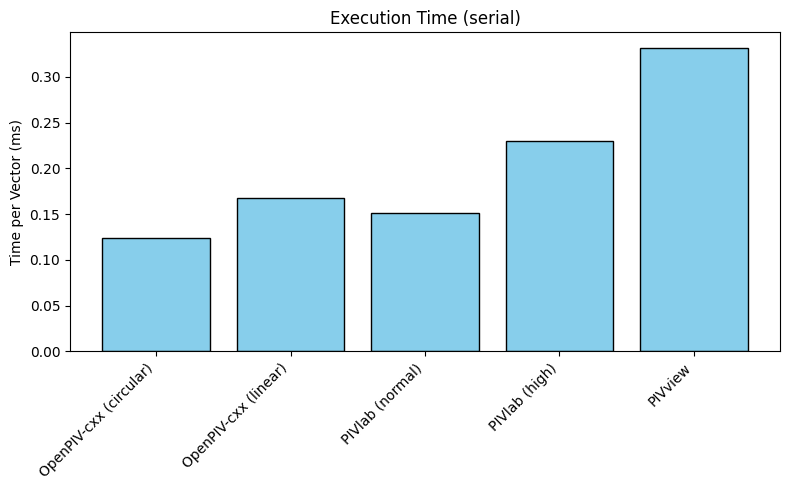

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(categories, serial, color='skyblue', edgecolor='black')

ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

ax.set_ylabel('Time per Vector (ms)')
ax.set_title('Execution Time (serial)')
fig.tight_layout()

#plt.savefig(f'test_execution_time_serial.png')

C:\Users\Research\AppData\Local\Temp\ipykernel_3944\2207323402.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


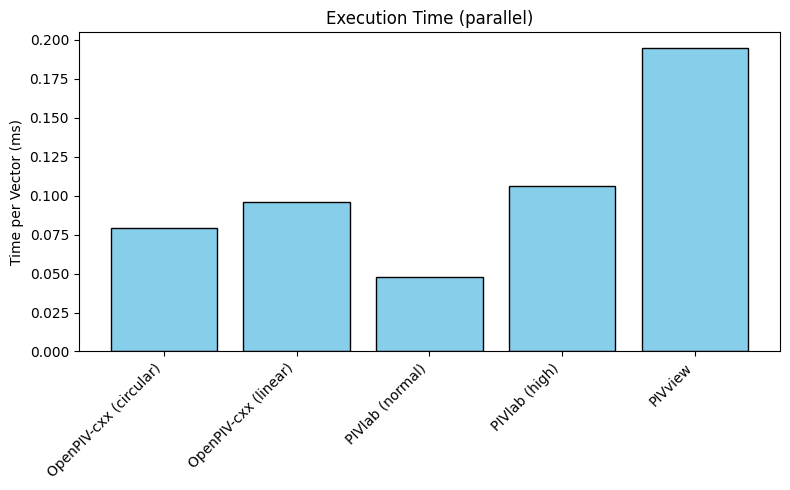

In [17]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(categories, threaded, color='skyblue', edgecolor='black')

ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

ax.set_ylabel('Time per Vector (ms)')
ax.set_title('Execution Time (parallel)')
fig.tight_layout()

#plt.savefig(f'test_execution_time_parallel.png')